In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt

In [2]:
import os
from dotenv import load_dotenv
from pathlib import Path

# Como o notebook está em 'corretor/src/3_avaliacao' e o .env em 'corretor',
# precisamos voltar duas pastas (../..) para achar o arquivo.
env_path = Path('../../.env')

# Carrega o arquivo explicitamente
load_dotenv(dotenv_path=env_path)

True

In [3]:
PATH_DADOS_ANONIMIZACAO_CORRETOR = os.getenv('PATH_DADOS_ANONIMIZACAO_CORRETOR')
PATH_DADOS_ANONIMIZACAO_BERT = os.getenv('PATH_DADOS_ANONIMIZACAO_BERT')
PATH_DADOS_ANONIMIZACAO_SPACY = os.getenv('PATH_DADOS_ANONIMIZACAO_SPACY')

PATH_BASE_ENTROPIA_CORRETOR = os.getenv('PATH_BASE_ENTROPIA_CORRETOR')
PATH_BASE_ENTROPIA_BERT = os.getenv('PATH_BASE_ENTROPIA_BERT')
PATH_BASE_ENTROPIA_SPACY = os.getenv('PATH_BASE_ENTROPIA_SPACY')

In [4]:
spacy_data = pd.read_csv(PATH_DADOS_ANONIMIZACAO_SPACY)
bertimbau_data = pd.read_csv(PATH_DADOS_ANONIMIZACAO_BERT)
corretor_data = pd.read_csv(PATH_DADOS_ANONIMIZACAO_CORRETOR)

In [5]:
merged_df = spacy_data.merge(bertimbau_data, on="n_bop", how="inner") \
                      .merge(corretor_data, on="n_bop", how="inner")

In [6]:
merged_df = merged_df.drop(columns=['relato','relato_tratado','corretor_qtd_tokens','corretor_qtd_gab_nomes','relato_x', "relato_tratado_x", "relato_y", "relato_tratado_y", "bertimbau_qtd_tokens", "bertimbau_qtd_gab_nomes"])

In [7]:
merged_df

,n_bop,nomes_x,spacy_qtd_tokens,spacy_qtd_pred_nomes,spacy_qtd_gab_nomes,spacy_nomes_acertados,nomes_y,bertimbau_qtd_pred_nomes,bertimbau_nomes_acertados,nomes,corretor_qtd_pred_nomes,corretor_nomes_acertados
0,1,"ALICE, MORAES, PAULO, SOUSA, MATOS",84.0,13.0,9.0,8.0,"ALICE, MORAES, PAULO, SOUSA, MATOS",12.0,8.0,"ALICE, MORAES, PAULO, SOUSA, MATOS",42.0,9.0
1,2,"RAFAELA, MARTINS, MARIA, SILVA, FERNANDO, CRUZ...",88.0,12.0,10.0,9.0,"RAFAELA, MARTINS, MARIA, SILVA, FERNANDO, CRUZ...",10.0,9.0,"RAFAELA, MARTINS, MARIA, SILVA, FERNANDO, CRUZ...",32.0,10.0
2,3,"RICARDO, GONÇALVES, ANDRÉ, FERNANDA, LIMA, OLI...",91.0,8.0,7.0,5.0,"RICARDO, GONÇALVES, ANDRÉ, FERNANDA, LIMA, OLI...",10.0,5.0,"RICARDO, GONÇALVES, ANDRÉ, FERNANDA, LIMA, OLI...",37.0,7.0
3,4,"PEDRO, SANTOS, LUISA, FERNANDES",76.0,5.0,5.0,4.0,"PEDRO, SANTOS, LUISA, FERNANDES",6.0,4.0,"PEDRO, SANTOS, LUISA, FERNANDES",29.0,5.0
4,5,"JOANA, MARTINS, RENATA, COSTA",81.0,11.0,9.0,8.0,"JOANA, MARTINS, RENATA, COSTA",10.0,8.0,"JOANA, MARTINS, RENATA, COSTA",36.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1881,1882,"CLÁUDIA, SOARES, ALMEIDA, PEDRO, LARISSA, GOME...",151.0,22.0,20.0,16.0,"CLÁUDIA, SOARES, ALMEIDA, PEDRO, LARISSA, GOME...",23.0,17.0,"CLÁUDIA, SOARES, ALMEIDA, PEDRO, LARISSA, GOME...",70.0,20.0
1882,1883,"RENATO, AUGUSTO, MOREIRA, FERNANDA, LOPES, SAM...",166.0,26.0,15.0,15.0,"RENATO, AUGUSTO, MOREIRA, FERNANDA, LOPES, SAM...",15.0,14.0,"RENATO, AUGUSTO, MOREIRA, FERNANDA, LOPES, SAM...",73.0,15.0
1883,1884,"GERTRUDES, SILVA, CARNEIRO, CLARISSA, DIEGO, H...",158.0,22.0,17.0,9.0,"GERTRUDES, SILVA, CARNEIRO, CLARISSA, DIEGO, H...",21.0,16.0,"GERTRUDES, SILVA, CARNEIRO, CLARISSA, DIEGO, H...",69.0,17.0
1884,1885,"ELIANA, COSTA, SILVA, MARIANA, FREITAS, RAFAEL...",123.0,21.0,18.0,16.0,"ELIANA, COSTA, SILVA, MARIANA, FREITAS, RAFAEL...",17.0,15.0,"ELIANA, COSTA, SILVA, MARIANA, FREITAS, RAFAEL...",57.0,18.0


In [8]:
copy_merged_df = merged_df.copy()

In [9]:
copy_merged_df.sort_values(['spacy_qtd_tokens'], ascending=False)

,n_bop,nomes_x,spacy_qtd_tokens,spacy_qtd_pred_nomes,spacy_qtd_gab_nomes,spacy_nomes_acertados,nomes_y,bertimbau_qtd_pred_nomes,bertimbau_nomes_acertados,nomes,corretor_qtd_pred_nomes,corretor_nomes_acertados
1259,1260,"MARIANA, DOS, SANTOS, GABRIEL, ALVES",296.0,11.0,8.0,6.0,"MARIANA, DOS, SANTOS, GABRIEL, ALVES",12.0,8.0,"MARIANA, DOS, SANTOS, GABRIEL, ALVES",94.0,8.0
104,105,"CARLOS, EDUARDO, ROCHA, JOÃO, MARIA, CLAUDIO, ...",294.0,26.0,15.0,15.0,"CARLOS, EDUARDO, ROCHA, JOÃO, MARIA, CLAUDIO, ...",18.0,14.0,"CARLOS, EDUARDO, ROCHA, JOÃO, MARIA, CLAUDIO, ...",107.0,15.0
1147,1148,"JOÃO, CARDOSO, DE, ALMEIDA, DR., PAULO, ANDRAD...",294.0,19.0,7.0,6.0,"JOÃO, CARDOSO, DE, ALMEIDA, DR., PAULO, ANDRAD...",9.0,6.0,"JOÃO, CARDOSO, DE, ALMEIDA, DR., PAULO, ANDRAD...",110.0,7.0
87,88,"MARIANA, GOMES, JOSÉ, CARLOS, MELLO, HEITOR, S...",284.0,20.0,13.0,11.0,"MARIANA, GOMES, JOSÉ, CARLOS, MELLO, HEITOR, S...",14.0,11.0,"MARIANA, GOMES, JOSÉ, CARLOS, MELLO, HEITOR, S...",82.0,13.0
1153,1154,"PAULO, GONÇALVES, DE, LIMA, RICARDO, SOUSA, ME...",283.0,10.0,8.0,5.0,"PAULO, GONÇALVES, DE, LIMA, RICARDO, SOUSA, ME...",11.0,7.0,"PAULO, GONÇALVES, DE, LIMA, RICARDO, SOUSA, ME...",102.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1102,1103,"CARLA, FERRAZ, MARCOS, PRADO",34.0,5.0,4.0,4.0,"CARLA, FERRAZ, MARCOS, PRADO",7.0,4.0,"CARLA, FERRAZ, MARCOS, PRADO",7.0,3.0
1107,1108,"JORGE, SILVA, ANDRÉ, LOPES",33.0,5.0,4.0,4.0,"JORGE, SILVA, ANDRÉ, LOPES",7.0,4.0,"JORGE, SILVA, ANDRÉ, LOPES",8.0,4.0
1101,1102,"JOSÉ, OLIVEIRA, CARLOS, SOUSA",33.0,5.0,4.0,4.0,"JOSÉ, OLIVEIRA, CARLOS, SOUSA",7.0,4.0,"JOSÉ, OLIVEIRA, CARLOS, SOUSA",10.0,4.0
1104,1105,"ISABEL, ANDRADE, MARINA, GOMES",31.0,5.0,4.0,4.0,"ISABEL, ANDRADE, MARINA, GOMES",6.0,4.0,"ISABEL, ANDRADE, MARINA, GOMES",12.0,4.0


In [8]:
# copy_merged_df  = copy_merged_df.drop(columns=['n_bop', ])

# 1) qtd geral tokens - marcar o outliers

In [10]:
copy_merged_df.shape

(1886, 12)

In [11]:
qtd_geral_tokens = copy_merged_df[['spacy_qtd_tokens', "spacy_qtd_gab_nomes"]]

In [12]:
qtd_geral_tokens = qtd_geral_tokens.rename(columns={"spacy_qtd_tokens":"Number of tokens", "spacy_qtd_gab_nomes":"Number of correct answers"})

In [13]:
qtd_geral_tokens = qtd_geral_tokens.sort_values(['Number of tokens'], ascending=True)

In [14]:
qtd_geral_tokens = qtd_geral_tokens.reset_index(drop=True)

In [15]:
copy_merged_df.shape

(1886, 12)

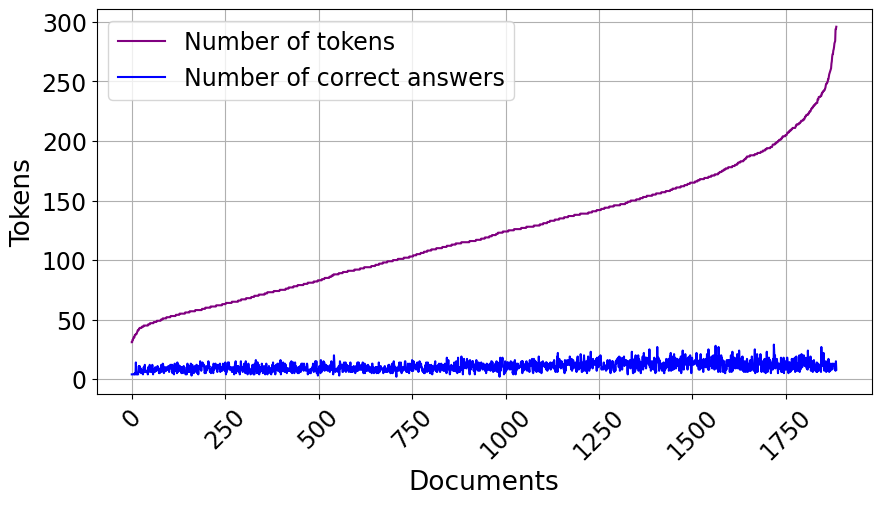

In [16]:
valores_spacy = qtd_geral_tokens.iloc[0].values

plt.figure(figsize=(10, 5))

cores = {"Number of tokens": "purple", "Number of correct answers": "blue"}

for coluna in qtd_geral_tokens.columns:
    cor = cores.get(coluna, "black")
    plt.plot(qtd_geral_tokens.index, qtd_geral_tokens[coluna], linestyle='-', label=coluna, color=cor)

plt.xlabel("Documents", fontsize=19)
plt.ylabel("Tokens", fontsize=19)
plt.xticks(rotation=45, fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=17)
plt.grid(True)

plt.show()

# 2) qtd predição tokens 

In [17]:
copy_merged_df.shape

(1886, 12)

In [18]:
remove_outliers_copy_merged_df = copy_merged_df[copy_merged_df['spacy_qtd_tokens'] < 400]

In [19]:
remove_outliers_copy_merged_df.shape

(1886, 12)

In [20]:
copy_merged_df.columns

Index(['n_bop', 'nomes_x', 'spacy_qtd_tokens', 'spacy_qtd_pred_nomes',
       'spacy_qtd_gab_nomes', 'spacy_nomes_acertados', 'nomes_y',
       'bertimbau_qtd_pred_nomes', 'bertimbau_nomes_acertados', 'nomes',
       'corretor_qtd_pred_nomes', 'corretor_nomes_acertados'],
      dtype='object')

In [21]:
copy_merged_df.shape

(1886, 12)

In [22]:
qtd_pred_tokens = remove_outliers_copy_merged_df[["spacy_qtd_gab_nomes", "spacy_qtd_pred_nomes","bertimbau_qtd_pred_nomes", "corretor_qtd_pred_nomes"]]

In [ ]:
qtd_pred_tokens = qtd_pred_tokens.rename(columns={"spacy_qtd_gab_nomes":"Number of correct answers", "spacy_qtd_pred_nomes":"Spacy", "bertimbau_qtd_pred_nomes":"Bertimbau", "corretor_qtd_pred_nomes":"Module II"})

In [24]:
qtd_pred_tokens = qtd_pred_tokens.sort_values(['Module II Model'], ascending=True)

In [25]:
qtd_pred_tokens = qtd_pred_tokens.reset_index(drop=True)

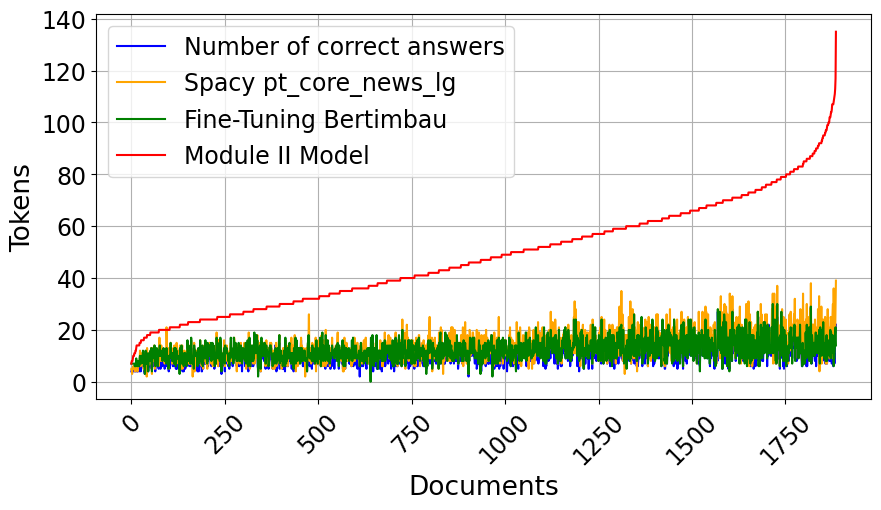

In [ ]:
valores_spacy = qtd_pred_tokens.iloc[0].values

plt.figure(figsize=(10, 5))

cores = {"Number of correct answers": "blue", "Spacy": "orange", "Bertimbau":"green", "Module II":"red"}

for coluna in qtd_pred_tokens.columns:
    cor = cores.get(coluna, "black")
    plt.plot(qtd_pred_tokens.index, qtd_pred_tokens[coluna], linestyle='-', label=coluna, color=cor)

plt.xlabel("Documents", fontsize=19)
plt.ylabel("Tokens", fontsize=19)
plt.xticks(rotation=45, fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=17)
plt.grid(True)

plt.show()

# 3) qtd acertos tokens

In [27]:
copy_merged_df.shape

(1886, 12)

In [28]:
copy_merged_df.columns

Index(['n_bop', 'nomes_x', 'spacy_qtd_tokens', 'spacy_qtd_pred_nomes',
       'spacy_qtd_gab_nomes', 'spacy_nomes_acertados', 'nomes_y',
       'bertimbau_qtd_pred_nomes', 'bertimbau_nomes_acertados', 'nomes',
       'corretor_qtd_pred_nomes', 'corretor_nomes_acertados'],
      dtype='object')

In [29]:
# copy_merged_df = copy_merged_df[copy_merged_df['qtd_nomes'] < 40]
remove_outliers_copy_merged_df = copy_merged_df[copy_merged_df['spacy_qtd_tokens'] < 400]

In [30]:
remove_outliers_copy_merged_df.shape

(1886, 12)

In [31]:
qtd_nomes = remove_outliers_copy_merged_df[["spacy_qtd_gab_nomes", "spacy_nomes_acertados","bertimbau_nomes_acertados", "corretor_nomes_acertados"]]

In [ ]:
qtd_nomes = qtd_nomes.rename(columns={"spacy_qtd_gab_nomes":"Number of correct answers", "spacy_nomes_acertados":"Spacy", "bertimbau_nomes_acertados":"Bertimbau", "corretor_nomes_acertados":"Module II"})

In [ ]:
qtd_nomes = qtd_nomes.sort_values(['Module II'], ascending=True)
qtd_nomes = qtd_nomes.reset_index(drop=True)

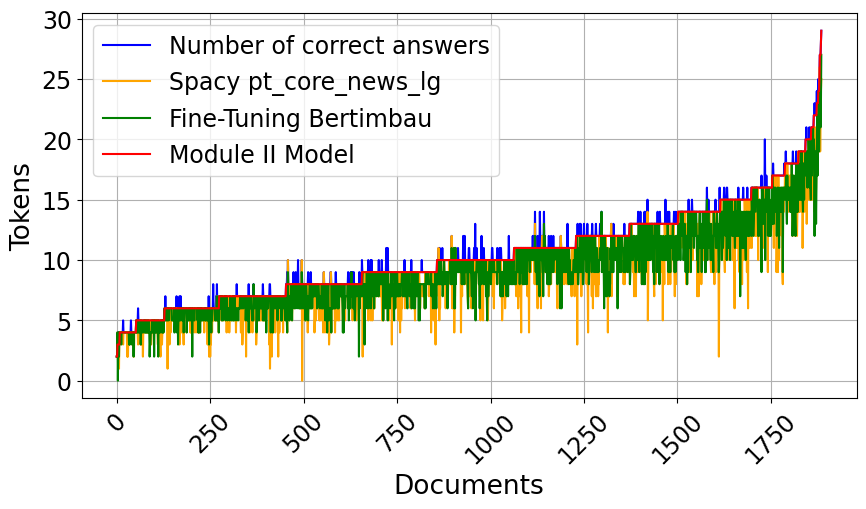

In [ ]:
valores_spacy = qtd_nomes.iloc[0].values

plt.figure(figsize=(10, 5))

cores = {"Number of correct answers": "blue", "Spacy": "orange", "Bertimbau":"green", "Module II":"red"}

for coluna in qtd_nomes.columns:
    cor = cores.get(coluna, "black")
    plt.plot(qtd_nomes.index, qtd_nomes[coluna], linestyle='-', label=coluna, color=cor)

plt.xlabel("Documents", fontsize=19)
plt.ylabel("Tokens", fontsize=19)
plt.xticks(rotation=45, fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=17)
plt.grid(True)

plt.show()

# Entropia

In [35]:
bertimbau_entropia = pd.read_csv(PATH_BASE_ENTROPIA_BERT)
spacy_entropia = pd.read_csv(PATH_BASE_ENTROPIA_SPACY)
corretor_entropia = pd.read_csv(PATH_BASE_ENTROPIA_CORRETOR)

In [36]:
merged_df = bertimbau_entropia.merge(spacy_entropia, on="n_bop", how="inner") \
                      .merge(corretor_entropia, on="n_bop", how="inner")

In [ ]:
merged_df = merged_df.rename(columns={"Entropy Corretor":"Entropy Module II"})

In [38]:
merged_df

,n_bop,bertimbau_text_orig,Entropy Bertimbau,spacy_text_orig,Entropy Spacy,corretor_text_orig,Entropy Module II Model
0,1,4.476728,4.551120,4.476728,4.545772,4.328201,4.187402
1,2,4.545204,4.590244,4.545204,4.591376,4.399838,4.297320
2,3,4.530039,4.591059,4.530039,4.586358,4.350131,4.191190
3,4,4.470348,4.528648,4.470348,4.522342,4.326459,4.268169
4,5,4.500206,4.567558,4.500206,4.567299,4.331277,4.094836
...,...,...,...,...,...,...,...
1881,1882,4.499044,4.565515,4.499044,4.572396,4.322932,4.095629
1882,1883,4.505535,4.566074,4.505535,4.570442,4.351737,4.119345
1883,1884,4.527272,4.589951,4.527272,4.591729,4.392405,4.065020
1884,1885,4.516227,4.593836,4.516227,4.593427,4.366220,4.081523


In [ ]:
compare_entropy = merged_df[["bertimbau_text_orig", "Entropy Bertimbau","Entropy Spacy", "Entropy Module II"]]

In [40]:
compare_entropy

,bertimbau_text_orig,Entropy Bertimbau,Entropy Spacy,Entropy Module II Model
0,4.476728,4.551120,4.545772,4.187402
1,4.545204,4.590244,4.591376,4.297320
2,4.530039,4.591059,4.586358,4.191190
3,4.470348,4.528648,4.522342,4.268169
4,4.500206,4.567558,4.567299,4.094836
...,...,...,...,...
1881,4.499044,4.565515,4.572396,4.095629
1882,4.505535,4.566074,4.570442,4.119345
1883,4.527272,4.589951,4.591729,4.065020
1884,4.516227,4.593836,4.593427,4.081523


In [ ]:
# Entropy anonymized texts by Bert
compare_entropy = compare_entropy.rename(columns={"bertimbau_text_orig":"Entropy Original Documents", "Entropy Spacy" : "Entropy Spacy", "Entropy Bertimbau" : "Entropy Bertimbau"})
compare_entropy = compare_entropy.sort_values(['Entropy Original Documents'], ascending=True)
compare_entropy = compare_entropy.reset_index(drop=True)

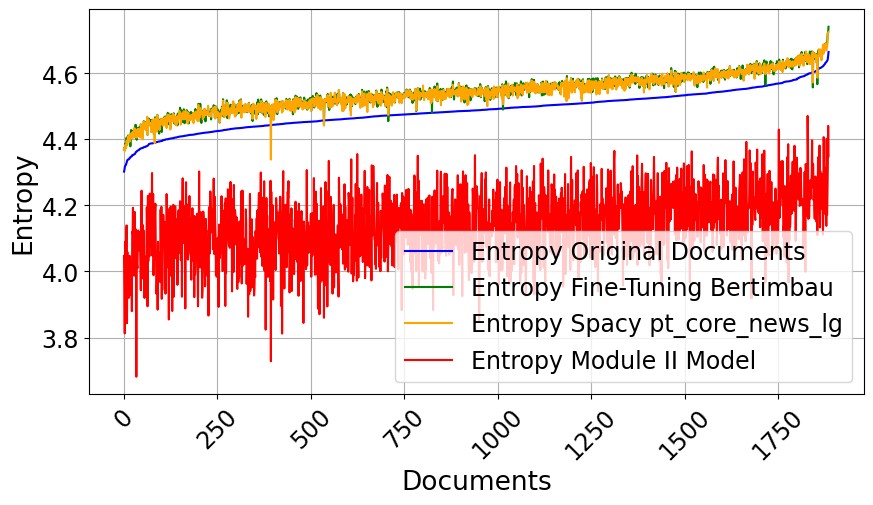

In [ ]:
valores_spacy = compare_entropy.iloc[0].values

plt.figure(figsize=(10, 5))

cores = {"Entropy Original Documents": "blue", "Entropy Bertimbau": "green", "Entropy Spacy":"orange", "Entropy Module II":"red"}

for coluna in compare_entropy.columns:
    cor = cores.get(coluna, "black")
    plt.plot(compare_entropy.index, compare_entropy[coluna], linestyle='-', label=coluna, color=cor)

plt.xlabel("Documents", fontsize=19)
plt.ylabel("Entropy", fontsize=19)
plt.xticks(rotation=45, fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=17)
plt.grid(True)

plt.show()